In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns


# Load the dataset
df = pd.read_csv(r'C:\Users\HP\Downloads\EVALUATION PROJECT\Machine Learning\hotel_bookings.csv')


In [4]:
print(df.columns.tolist())

# Here - df refers to the DataFrame (created from a CSV  file).
# df.columns returns an Index object containing all the column names.
# .tolist() converts that Index into a Python list.


['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [5]:
print("\nData Types:")
print(df.dtypes)

# it give all the data types


Data Types:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                

In [6]:
print(df.head())
# it print all the heads of the CSV file

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

In [7]:
print(df.tail())

             hotel  is_canceled  lead_time  arrival_date_year  \
119385  City Hotel            0         23               2017   
119386  City Hotel            0        102               2017   
119387  City Hotel            0         34               2017   
119388  City Hotel            0        109               2017   
119389  City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
119385             August                        35   
119386             August                        35   
119387             August                        35   
119388             August                        35   
119389             August                        35   

        arrival_date_day_of_month  stays_in_weekend_nights  \
119385                         30                        2   
119386                         31                        2   
119387                         31                        2   
119388                        

In [8]:
print(df.describe())
# It is a quick way to generate summary statistics for all numeric columns in the DataFrame


         is_canceled      lead_time  arrival_date_year  \
count  119390.000000  119390.000000      119390.000000   
mean        0.370416     104.011416        2016.156554   
std         0.482918     106.863097           0.707476   
min         0.000000       0.000000        2015.000000   
25%         0.000000      18.000000        2016.000000   
50%         0.000000      69.000000        2016.000000   
75%         1.000000     160.000000        2017.000000   
max         1.000000     737.000000        2017.000000   

       arrival_date_week_number  arrival_date_day_of_month  \
count             119390.000000              119390.000000   
mean                  27.165173                  15.798241   
std                   13.605138                   8.780829   
min                    1.000000                   1.000000   
25%                   16.000000                   8.000000   
50%                   28.000000                  16.000000   
75%                   38.000000            

#  ●	Data Cleaning And Preprocessing

### Q1. ○	Missing Data Handling: Identify and handle missing values in columns like children, country, and agent. Decide whether to impute missing values or remove rows with missing data.

In [9]:
# Identify Missing Values
missing_summary = df.isnull().sum() 
# it will checks every cell in the DataFrame for missing values and returns with  missing values.

missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)
#- Filters out columns that have zero missing values and keeps only columns with at least one missing value then sort the result in descending order

print(missing_summary)

company     112593
agent        16340
country        488
children         4
dtype: int64


In [10]:
# Fix missing values
# Replaces all missing values in the column with 0.
# inplace=True means the change is applied directly to the DataFrame.

df['company'].fillna(0, inplace=True)
df['agent'].fillna(0, inplace=True)
df['country'].fillna('Unknown', inplace=True)
df['children'].fillna(0, inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_18672\375996198.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['company'].fillna(0, inplace=True)
C:\Users\HP\AppData\Local\Temp\ipykernel_18672\375996198.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'd

In [11]:
# Convert agent and company to integer
df['agent'] = df['agent'].astype(int)
df['company'] = df['company'].astype(int)

In [15]:
print(df.dtypes)

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [18]:
# Check the wether missing values present or  no missing values remain in those columns.
# If return all zeros that meaning no missing values remain.

print(df[['company', 'agent', 'country', 'children']].isnull().sum())

company     0
agent       0
country     0
children    0
dtype: int64


### Q 2. ○	Outlier Detection: Check for anomalies in columns like adr (extreme values) and lead_time (very high values may need handling).

In [19]:
# Check for anomalies in columns first
# adr stands for Average Daily Rate 
# lead_time is the number of days between booking and arrival.

print(df['adr'].describe())
print(df['lead_time'].describe())

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64
count    119390.000000
mean        104.011416
std         106.863097
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: lead_time, dtype: float64


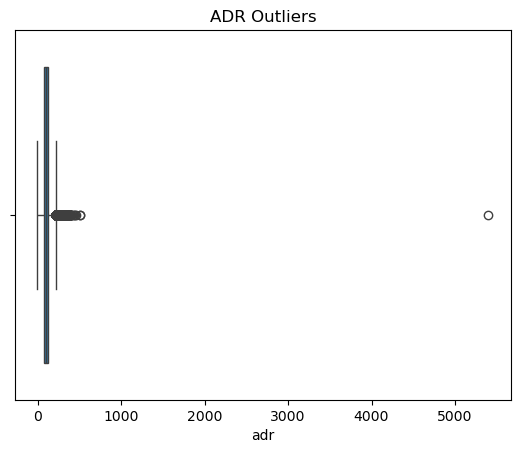

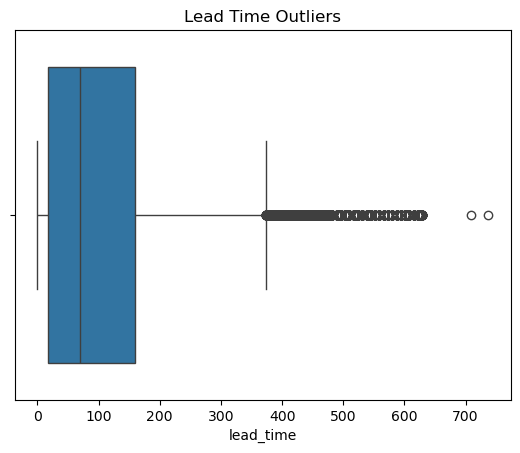

In [20]:
# Now make a boxplot for better visualisation of the adr and lead_time as
# ADR
sns.boxplot(x=df['adr'])
plt.title("ADR Outliers")
plt.show()

# Lead Time
sns.boxplot(x=df['lead_time'])
plt.title("Lead Time Outliers")
plt.show()


### Q 3. ○	Data Type Conversion: Ensure all data columns have the correct data types.

In [21]:
# Check Current Data Type
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [31]:
# Convert categorical columns
categorical_columns = [
    'hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
    'distribution_channel', 'reserved_room_type', 'assigned_room_type',
    'deposit_type', 'customer_type', 'reservation_status'
]

for columns in categorical_columns:
    df[columns] = df[columns].astype('category')

# Convert reservation date to datetime
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# Convert children to integer after filling missing values
df['children'] = df['children'].fillna(0).astype(int)

In [32]:
df.info()
# Category types for repeated text columns
# datetime64 for reservation dates
# int64 for cleaned numeric columns


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   hotel                           119390 non-null  category      
 1   is_canceled                     119390 non-null  int64         
 2   lead_time                       119390 non-null  int64         
 3   arrival_date_year               119390 non-null  int64         
 4   arrival_date_month              119390 non-null  category      
 5   arrival_date_week_number        119390 non-null  int64         
 6   arrival_date_day_of_month       119390 non-null  int64         
 7   stays_in_weekend_nights         119390 non-null  int64         
 8   stays_in_week_nights            119390 non-null  int64         
 9   adults                          119390 non-null  int64         
 10  children                        119390 non-null  int64  

# ●	Feature Engineering

### Q 1.   ○	Feature Scaling: Apply scaling techniques to numerical features.

In [29]:
# For this first Import the scaler
from sklearn.preprocessing import StandardScaler

In [33]:
# Now Select numerical columns to Apply Scaling techniques to numerical features
numerical_columns = [
    'lead_time', 'arrival_date_week_number', 'arrival_date_day_of_month',
    'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
    'babies', 'previous_cancellations', 'previous_bookings_not_canceled',
    'booking_changes', 'agent', 'company', 'days_in_waiting_list',
    'adr', 'required_car_parking_spaces', 'total_of_special_requests'
]

In [34]:
# Now Apply Scaling
scaler = StandardScaler()
df[numerical_columns] = scaler.fit_transform(df[numerical_columns])

In [35]:
# Check Wether Scaling Applied or not
df[numerical_columns].describe()

,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05,1.193900e+05
mean,6.094277e-17,-1.295034e-16,2.475800e-17,1.197430e-16,-2.761469e-17,3.237585e-17,-3.999369e-17,2.047296e-17,-3.142362e-17,2.047296e-17,3.428031e-17,9.141416e-17,3.237585e-17,3.904146e-17,2.513889e-16,-5.713385e-18,-5.332493e-17
std,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00,1.000004e+00
min,-9.733187e-01,-1.923191e+00,-1.685297e+00,-9.288904e-01,-1.310240e+00,-3.204792e+00,-2.606586e-01,-8.157926e-02,-1.031795e-01,-9.155477e-02,-3.389899e-01,-6.984065e-01,-1.997484e-01,-1.319236e-01,-2.141286e+00,-2.548729e-01,-7.206941e-01
25%,-8.048782e-01,-8.206620e-01,-8.881022e-01,-9.288904e-01,-7.862072e-01,2.478973e-01,-2.606586e-01,-8.157926e-02,-1.031795e-01,-9.155477e-02,-3.389899e-01,-6.330723e-01,-1.997484e-01,-1.319236e-01,-6.439250e-01,-2.548729e-01,-7.206941e-01
50%,-3.276301e-01,6.136141e-02,2.297730e-02,7.250220e-02,-2.621744e-01,2.478973e-01,-2.606586e-01,-8.157926e-02,-1.031795e-01,-9.155477e-02,-3.389899e-01,-6.144054e-01,-1.997484e-01,-1.319236e-01,-1.435844e-01,-2.548729e-01,-7.206941e-01
75%,5.239303e-01,7.963809e-01,8.201718e-01,1.073895e+00,2.618584e-01,2.478973e-01,-2.606586e-01,-8.157926e-02,-1.031795e-01,-9.155477e-02,-3.389899e-01,7.202781e-01,-1.997484e-01,-1.319236e-01,4.782547e-01,-2.548729e-01,5.406659e-01
max,5.923385e+00,1.898910e+00,1.731251e+00,1.809757e+01,2.489140e+01,9.174417e+01,2.483007e+01,1.025501e+02,3.069036e+01,4.799081e+01,3.185465e+01,4.294990e+00,9.866310e+00,2.209074e+01,1.048404e+02,3.235957e+01,5.586106e+00


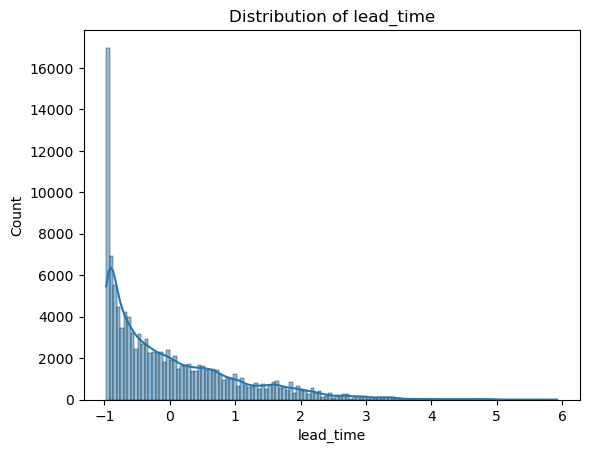

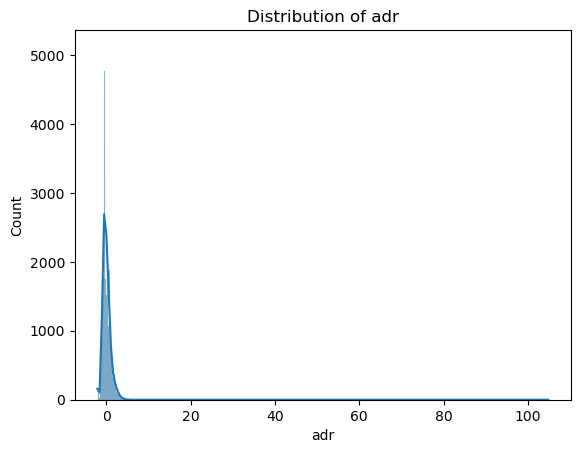

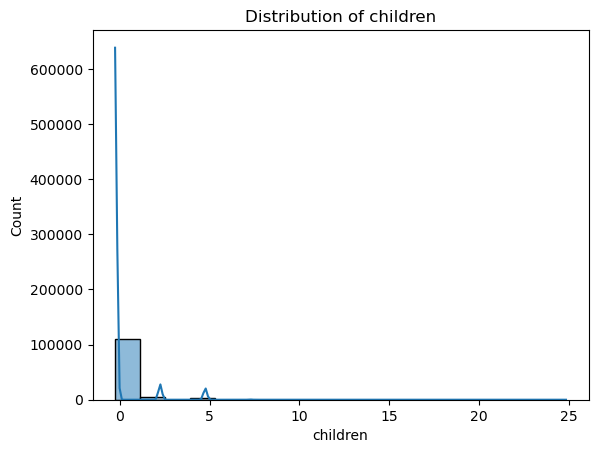

In [37]:
# Plot distribution of a few scaled features
for col in ['lead_time', 'adr', 'children']:
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()
# If scaling is applied then the plots will be centered around 0
# and the shape will resemble a standard normal distribution (bell curve)


### ○ 2.	Categorical Grouping: Group bookings into three categories based on lead_time:
              ■	Short: lead_time < 30 days
              ■	Medium: 30 days < lead_time < 90 days
              ■	Large: 90 days > lead_time


In [39]:
def lead_time_group(value):
    if value < 30:
        return 'Short' # It will show Short lead_time
    elif value < 90:
        return 'Medium' # It will show medium lead_time
    else:
        return 'Large' # It will show Large lead_time

In [40]:
df['lead_time_category'] = df['lead_time'].apply(lead_time_group)

In [41]:
df['lead_time_category'].value_counts()

lead_time_category
Short    119390
Name: count, dtype: int64

# ●	Advanced Filtering And Parameterization

### Q 1. ○	Find High-Risk Customers: Retrieve a list of customers who had multiple cancellations in the past.

In [43]:
# Filter Customers with Multiple Cancellations
high_risk_customers = df[df['previous_cancellations'] > 1]

In [44]:
# display a few columns to analyze their behavior
high_risk_customers[['agent', 'company', 'previous_cancellations', 'is_canceled', 'lead_time', 'country']].head()

,agent,company,previous_cancellations,is_canceled,lead_time,country
13805,-0.698406,1.542811,1.081188,1,-0.954603,Unknown
13811,-0.698406,-0.199748,1.081188,1,-0.308914,Unknown
13825,-0.698406,0.782758,1.081188,0,-0.917172,PRT
13826,-0.698406,0.782758,1.081188,0,-0.907814,PRT
13827,-0.698406,0.782758,1.081188,0,-0.898456,PRT


In [45]:
# Now count how many unique customers are high-risk
high_risk_count = high_risk_customers['agent'].nunique()
print("Number of high-risk agents:", high_risk_count)

Number of high-risk agents: 89


### Q. 2 ○	Most Frequent Guests: Identify the most frequent guests based on repeated bookings.

In [46]:
#  Filter Repeated Guests
repeated_guests = df[df['is_repeated_guest'] == 1]

In [47]:
frequent_guests = repeated_guests.groupby('agent').size().sort_values(ascending=False)
print(frequent_guests.head(10))  # Top 10 frequent agents

agent
-0.698406    2365
 1.541622     255
-0.689073     187
-0.614405     147
 1.634956     102
 0.066937      76
-0.642406      55
-0.073065      42
 0.178938      41
-0.567738      29
dtype: int64


### Q 3. ○	Seasonal Booking Trends: Identify peak booking months and trends across different hotels.

In [48]:
# Count Bookings by Month and Hotel
monthly_trends = df.groupby(['arrival_date_month', 'hotel']).size().reset_index(name='booking_count')

C:\Users\HP\AppData\Local\Temp\ipykernel_18672\1202520632.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_trends = df.groupby(['arrival_date_month', 'hotel']).size().reset_index(name='booking_count')


In [50]:
# Sort Months Chronologically
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_trends['arrival_date_month'] = pd.Categorical(
    monthly_trends['arrival_date_month'], categories=month_order, ordered=True
)
monthly_trends = monthly_trends.sort_values('arrival_date_month')

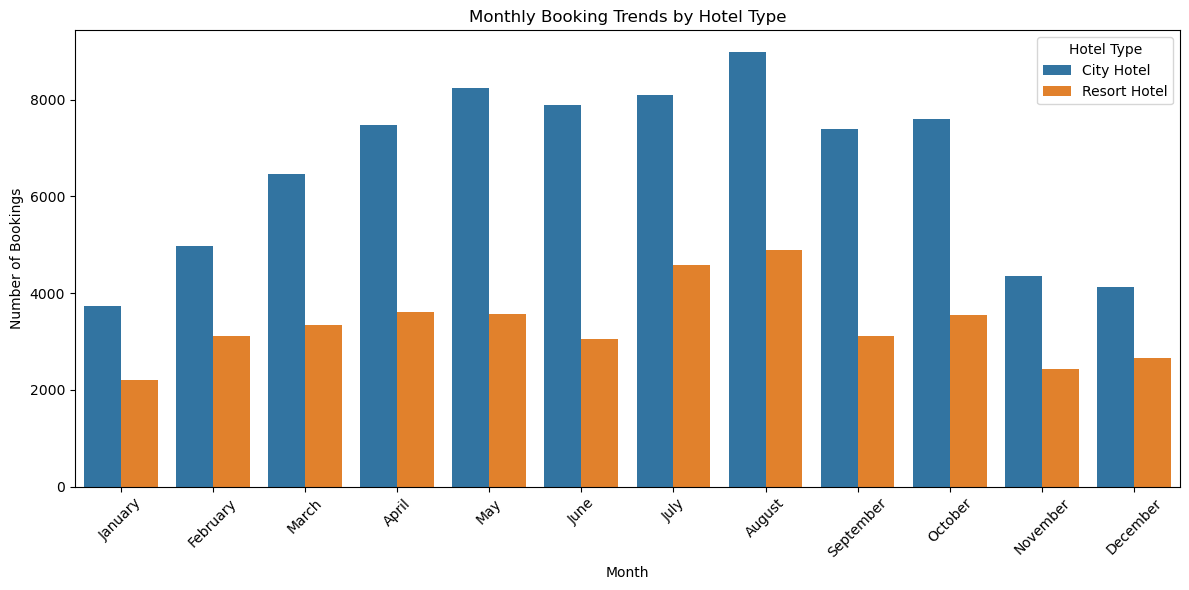

In [51]:
plt.figure(figsize=(12, 6))
sns.barplot(data=monthly_trends, x='arrival_date_month', y='booking_count', hue='hotel')
plt.title('Monthly Booking Trends by Hotel Type')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='Hotel Type')
plt.tight_layout()
plt.show()


# ●	Model Building

### ○ Q 1.	Split The Dataset: Split the dataset into training and testing sets (e.g., 80% training, 20% testing).

In [52]:
# Import the function

from sklearn.model_selection import train_test_split

# Define your features and target

X = df.drop('is_canceled', axis=1)  # Features
y = df['is_canceled']               # Target

In [53]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [54]:
# Confirm the split
print("Training set size:", X_train.shape) # Training set size
print("Testing set size:", X_test.shape) # Testing set size

Training set size: (95512, 32)
Testing set size: (23878, 32)


### ○ Q 2.	Experiment with models, mainly logistic regression, decision tree, random forest, gradient boosting machines, support vector machines.

In [ ]:
!pip install xgboost

In [55]:
# Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score



In [56]:

# features and target which i already wrote earlier(above) but for just understanding i write this code again.
X = df.drop('is_canceled', axis=1)
y = df['is_canceled']

# Encode categorical columns
X = pd.get_dummies(X, drop_first=True)

# Convert boolean columns to integers
X = X.apply(lambda col: col.astype(int) if col.dtype == 'bool' else col)

# Fill missing values (NaNs)
X = X.fillna(0)


In [57]:
# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [58]:

# Define models
models = [
    LogisticRegression(max_iter=1000),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    SVC()
]

model_names = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM']


In [60]:

# Train and evaluate each model
for name, model in zip(model_names, models):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.2f}")

DTypePromotionError: The DType <class 'numpy.dtypes.DateTime64DType'> could not be promoted by <class 'numpy.dtypes.Float64DType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Int64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Int64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'>, <class 'numpy.dtypes.Float64DType'

### ○ Q 3.	Hyperparameter Tuning: Use Grid Search or Random Search to optimize hyperparameters.

In [ ]:
# Define Hyperparameter Grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}


In [ ]:
# Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)
print("Best Grid Search Parameters:", grid_search.best_params_)


In [ ]:
# Evaluate Best Model
best_model = grid_search.best_estimator
y_pred = best_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

# ●	Model Testing

### Q 1. ○	Evaluate performance using performance metrics.
### ○	Use cross-validation techniques.


In [ ]:
#Use Cross-Validation
from sklearn.model_selection import cross_val_score

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    print(f"{name} Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

In [ ]:
# Evaluate with Performance Metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))